# Portafolio de Estadística: Pruebas de Normalidad, T de Student, ANOVA y Predicción (LTRM)

**Enlace al Dataset original:** [https://www.umesc.usgs.gov/data_library/fisheries/fish1_query.html](https://www.umesc.usgs.gov/data_library/fisheries/fish1_query.html)  
**Dataset de trabajo:** `df_limpio.csv` *(El conjunto de datos ya fue sometido a un proceso previo de limpieza, eliminación de nulos e inconsistencias).*

<div align="center">
  <a href="https://www.umesc.usgs.gov/data_library/fisheries/fish1_query.html">
    <img src="https://img.shields.io/badge/-🗄️_Ir_a_la_Base_de_Datos-238636?style=for-the-badge" alt="Botón Base de Datos" />
  </a>
</div>

<div align="center">
  <a href="https://axiscrazy.github.io/Probabilidad-y-estadistica-2/index.html">
    <img src="https://img.shields.io/badge/-⬅️_Regresar_a_la_página_web-007ACC?style=for-the-badge" alt="Botón Regresar" />
  </a>
</div>

### Objetivo del análisis
Evaluar si existen diferencias estadísticamente significativas en el peso (`weight`) entre las distintas especies de peces (`fishcode`) registradas en el programa LTRM mediante pruebas **T de Student** y **ANOVA de un factor**, previa validación de tamaño de muestra y normalidad. Finalmente, construir modelos predictivos que permitan estimar el **peso** y el **tamaño** (`length`) a partir de la especie y su relación morfométrica.

In [2]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv('df_limpio.csv')
df = df[(df['weight'] > 0) & (df['length'] > 0)].copy()

print(f"Registros disponibles: {df.shape[0]}")
print(f"Especies únicas (fishcode): {df['fishcode'].nunique()}")
df[['fishcode', 'length', 'weight']].head()

Registros disponibles: 92221
Especies únicas (fishcode): 100


,fishcode,length,weight
0,LMBS,174.0,75.0
1,LMBS,124.0,29.0
2,BLGL,149.0,84.0
3,BLGL,165.0,119.0
4,BLGL,151.0,82.0


### 1. Verificación y Cálculo de Tamaño de Muestra

Antes de aplicar pruebas paramétricas comparativas (T de Student y ANOVA), verificamos dos criterios fundamentales sobre el tamaño de muestra:

1. **Tamaño de muestra mínimo poblacional ($n$):** Calculamos cuántos registros mínimos se requieren para estimar la media del peso con un **95% de confianza** ($Z = 1.96$) y un margen de error ($E$) equivalente al 5% de la desviación estándar:
$$ n = \left( \frac{Z_{\alpha/2} \cdot s}{E} \right)^2 $$
2. **Suficiencia por grupo ($n_i \ge 30$):** Para garantizar la validez del Teorema del Límite Central en cada especie comparada, seleccionaremos las **5 especies más abundantes** para la prueba ANOVA y las **2 especies más abundantes** para la prueba T de Student.

In [3]:
conteo_especies = df['fishcode'].value_counts()
top5_especies = conteo_especies.head(5).index.tolist()
top2_especies = conteo_especies.head(2).index.tolist()

df_top5 = df[df['fishcode'].isin(top5_especies)].copy()
df_top5['log_weight'] = np.log10(df_top5['weight'])
df_top5['log_length'] = np.log10(df_top5['length'])

z_crit = st.norm.ppf(0.975)
s_global = df_top5['log_weight'].std(ddof=1)
error_max = 0.05 * s_global
n_minimo = int(np.ceil((z_crit * s_global / error_max) ** 2))

resumen_muestra = df_top5.groupby('fishcode').agg(
    n=('weight', 'count'),
    media_peso=('weight', 'mean'),
    std_peso=('weight', 'std'),
    media_tamano=('length', 'mean')
).loc[top5_especies]
resumen_muestra['cumple_n_min_30'] = resumen_muestra['n'] >= 30

print(f"Tamaño de muestra mínimo teórico calculado (95% conf.): {n_minimo} registros")
print(f"Tamaño de muestra disponible en Top 5 especies: {len(df_top5)} registros")
print(f"¿Muestra global suficiente?: {'Sí' if len(df_top5) >= n_minimo else 'No'}\n")
print(resumen_muestra)

Tamaño de muestra mínimo teórico calculado (95% conf.): 1537 registros
Tamaño de muestra disponible en Top 5 especies: 52832 registros
¿Muestra global suficiente?: Sí

              n   media_peso     std_peso  media_tamano  cumple_n_min_30
fishcode                                                                
BLGL      18848    50.785625    54.135012    118.480953             True
LMBS       9564   195.280279   345.191886    178.760665             True
CNCF       8760   536.868249   800.815488    324.536530             True
GZSD       8036    75.588748   117.322859    169.401692             True
CARP       7624  2369.272141  1609.397921    522.364244             True


### 2. Pruebas de Normalidad (Escala Original vs. Transformación Logarítmica)

Las pruebas paramétricas como T de Student y ANOVA asumen que los datos (o la distribución de sus medias muestrales) se aproximan a una distribución normal. Debido al gran tamaño de muestra por especie, aplicamos la **prueba $K^2$ de D'Agostino-Pearson** bajo las siguientes hipótesis:

- $H_0$: Los datos de peso de la especie siguen una distribución normal.
- $H_1$: Los datos de peso de la especie **no** siguen una distribución normal.

Dado que los pesos biológicos suelen presentar un fuerte sesgo positivo hacia la derecha, comparamos la normalidad en la **escala original** (`weight`) frente a la **escala logarítmica** ($\log_{10}(\text{weight})$) y complementamos con análisis visual mediante histogramas y gráficos Q-Q.

Especie     n  K2_Original p_Original  K2_Log10     p_Log10
   BLGL 18848      7352.15 0.0000e+00   1206.12 1.2401e-262
   LMBS  9564      4769.62 0.0000e+00   1104.94 1.1639e-240
   CNCF  8760      5122.33 0.0000e+00    154.08  3.4744e-34
   GZSD  8036      5525.70 0.0000e+00    133.15  1.2216e-29
   CARP  7624      1850.44 0.0000e+00   2941.56  0.0000e+00


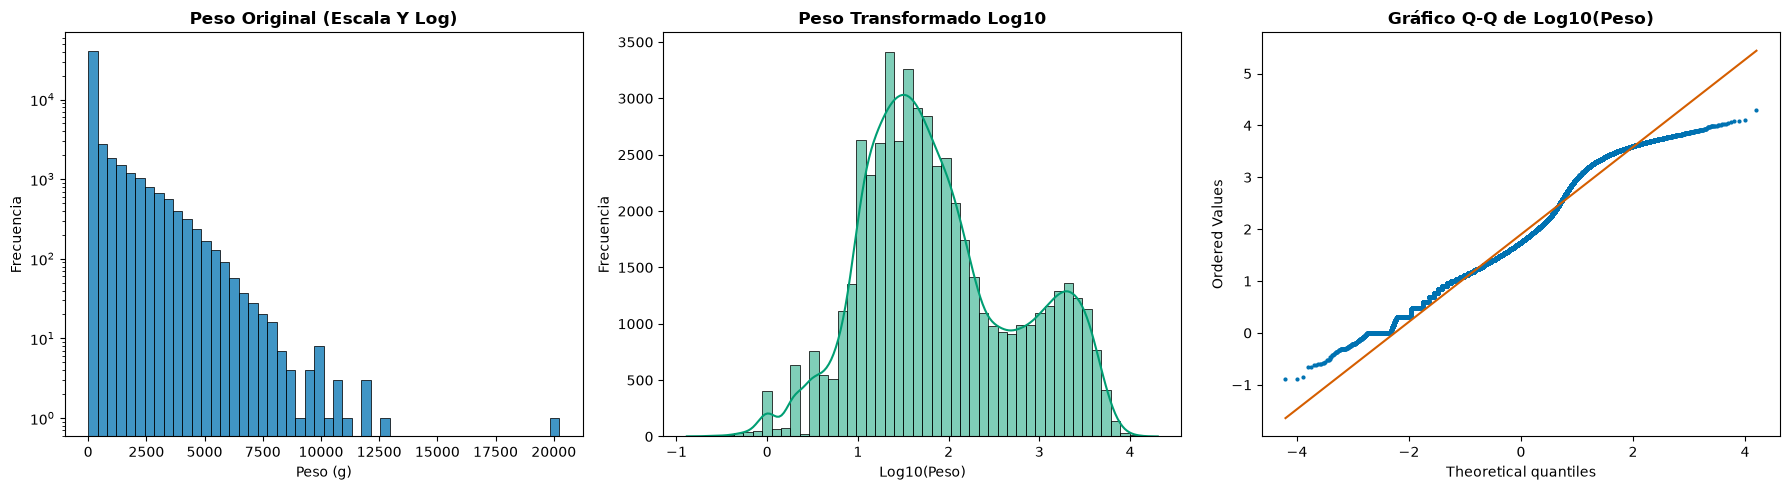

In [4]:
resultados_norm = []
for esp in top5_especies:
    datos_orig = df_top5[df_top5['fishcode'] == esp]['weight']
    datos_log = df_top5[df_top5['fishcode'] == esp]['log_weight']
    stat_o, p_o = st.normaltest(datos_orig)
    stat_l, p_l = st.normaltest(datos_log)
    resultados_norm.append({
        'Especie': esp,
        'n': len(datos_orig),
        'K2_Original': round(stat_o, 2),
        'p_Original': f"{p_o:.4e}",
        'K2_Log10': round(stat_l, 2),
        'p_Log10': f"{p_l:.4e}"
    })

df_norm = pd.DataFrame(resultados_norm)
print(df_norm.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_top5['weight'], bins=50, kde=False, ax=axes[0], color='#0072B2')
axes[0].set_yscale('log')
axes[0].set_title('Peso Original (Escala Y Log)', fontweight='bold')
axes[0].set_xlabel('Peso (g)')
axes[0].set_ylabel('Frecuencia')

sns.histplot(df_top5['log_weight'], bins=50, kde=True, ax=axes[1], color='#009E73')
axes[1].set_title('Peso Transformado Log10', fontweight='bold')
axes[1].set_xlabel('Log10(Peso)')
axes[1].set_ylabel('Frecuencia')

st.probplot(df_top5['log_weight'], dist='norm', plot=axes[2])
axes[2].get_lines()[0].set_color('#0072B2')
axes[2].get_lines()[0].set_markersize(2)
axes[2].get_lines()[1].set_color('#D55E00')
axes[2].set_title('Gráfico Q-Q de Log10(Peso)', fontweight='bold')

plt.tight_layout()
plt.show()

### 3. Prueba T de Student (Comparación entre las 2 Especies más Abundantes)

Comparamos si existe una diferencia significativa entre el peso medio (en escala $\log_{10}$) de las dos especies con mayor número de registros en el dataset.

**Hipótesis:**
- $H_0: \mu_1 = \mu_2$ *(No existe diferencia significativa en el peso medio entre ambas especies).*
- $H_1: \mu_1 \neq \mu_2$ *(Existe una diferencia significativa en el peso medio entre ambas especies).*

**Validación de varianzas:** Antes de calcular el estadístico $t$, se aplica la **prueba de Levene** ($\alpha = 0.05$) para determinar si las varianzas son iguales (T de Student clásica) o distintas (T de Welch).

$$ t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}} $$

Especies comparadas: BLGL (n=18848) vs LMBS (n=9564)
Prueba de Levene: estadístico = 695.3315, p-value = 2.0619e-151
Tipo de prueba aplicada: T de Welch (varianzas desiguales)
Media Log10 BLGL: 1.4304 (Media real: 50.79 g)
Media Log10 LMBS: 1.7188 (Media real: 195.28 g)
Estadístico t: -34.9804 | Valor crítico (+/-): 1.9600 | p-value: 2.1642e-258
Decisión: Rechazar H0 (existen diferencias significativas)


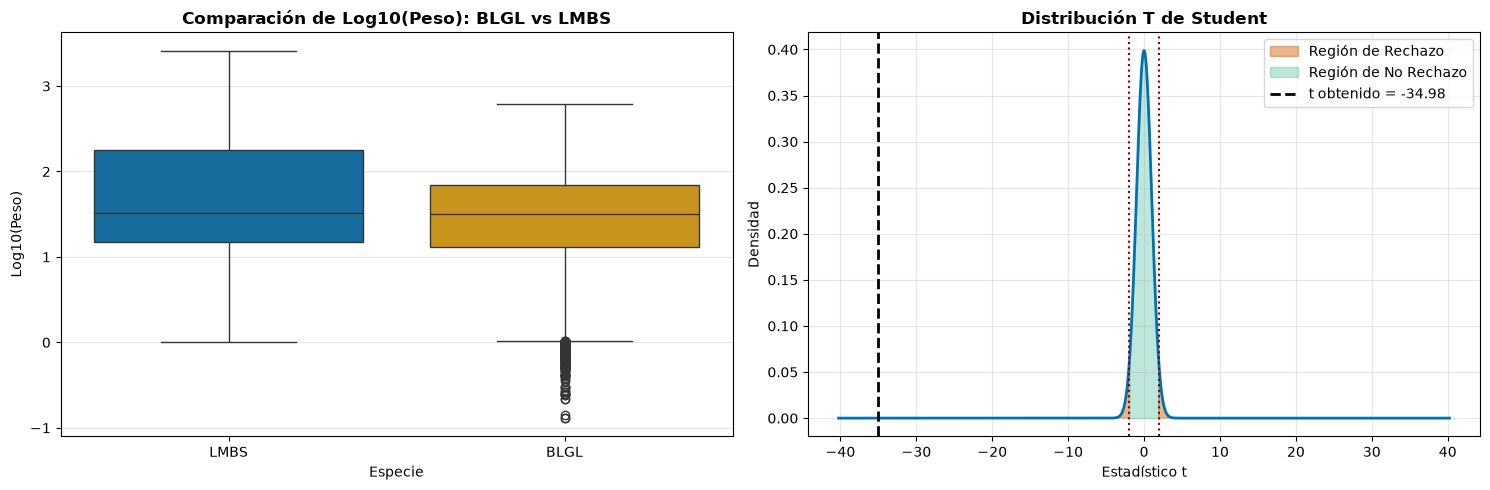

In [5]:
esp1, esp2 = top2_especies[0], top2_especies[1]
g1 = df_top5[df_top5['fishcode'] == esp1]['log_weight']
g2 = df_top5[df_top5['fishcode'] == esp2]['log_weight']

stat_lev, p_lev = st.levene(g1, g2)
varianzas_iguales = p_lev >= 0.05

t_stat, p_val_t = st.ttest_ind(g1, g2, equal_var=varianzas_iguales)
gl_t = len(g1) + len(g2) - 2
alpha = 0.05
t_crit = st.t.ppf(1 - alpha / 2, df=gl_t)

print(f"Especies comparadas: {esp1} (n={len(g1)}) vs {esp2} (n={len(g2)})")
print(f"Prueba de Levene: estadístico = {stat_lev:.4f}, p-value = {p_lev:.4e}")
print(f"Tipo de prueba aplicada: {'T de Student estándar' if varianzas_iguales else 'T de Welch (varianzas desiguales)'}")
print(f"Media Log10 {esp1}: {g1.mean():.4f} (Media real: {df_top5[df_top5['fishcode'] == esp1]['weight'].mean():.2f} g)")
print(f"Media Log10 {esp2}: {g2.mean():.4f} (Media real: {df_top5[df_top5['fishcode'] == esp2]['weight'].mean():.2f} g)")
print(f"Estadístico t: {t_stat:.4f} | Valor crítico (+/-): {t_crit:.4f} | p-value: {p_val_t:.4e}")
print(f"Decisión: {'Rechazar H0 (existen diferencias significativas)' if p_val_t < alpha else 'No rechazar H0'}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_top2 = df_top5[df_top5['fishcode'].isin(top2_especies)]
sns.boxplot(data=df_top2, x='fishcode', y='log_weight', hue='fishcode', legend=False, palette=['#0072B2', '#E69F00'], ax=axes[0])
axes[0].set_title(f'Comparación de Log10(Peso): {esp1} vs {esp2}', fontweight='bold')
axes[0].set_xlabel('Especie')
axes[0].set_ylabel('Log10(Peso)')
axes[0].grid(axis='y', alpha=0.3)

limite_x = max(abs(t_stat) * 1.15, 4.5)
x_t = np.linspace(-limite_x, limite_x, 1000)
y_t = st.t.pdf(x_t, df=gl_t)
axes[1].plot(x_t, y_t, color='#0072B2', linewidth=2)
axes[1].fill_between(x_t, y_t, where=(x_t <= -t_crit) | (x_t >= t_crit), color='#D55E00', alpha=0.45, label='Región de Rechazo')
axes[1].fill_between(x_t, y_t, where=(x_t > -t_crit) & (x_t < t_crit), color='#009E73', alpha=0.25, label='Región de No Rechazo')
axes[1].axvline(t_stat, color='black', linestyle='--', linewidth=2, label=f't obtenido = {t_stat:.2f}')
axes[1].axvline(-t_crit, color='darkred', linestyle=':', linewidth=1.5)
axes[1].axvline(t_crit, color='darkred', linestyle=':', linewidth=1.5)
axes[1].set_title('Distribución T de Student', fontweight='bold')
axes[1].set_xlabel('Estadístico t')
axes[1].set_ylabel('Densidad')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4. Análisis de Varianza (ANOVA de un Factor)

Para comparar simultáneamente el peso medio de las **5 especies más abundantes** sin inflar el error Tipo I, aplicamos un **ANOVA de un factor** sobre $\log_{10}(\text{weight})$.

**Hipótesis:**
- $H_0: \mu_1 = \mu_2 = \mu_3 = \mu_4 = \mu_5$ *(Todas las especies tienen el mismo peso medio).*
- $H_1$: Al menos una especie presenta un peso medio estadísticamente diferente.

$$ F = \frac{CM_{\text{entre grupos}}}{CM_{\text{dentro de grupos}}} $$

En caso de rechazar $H_0$, se ejecuta la prueba **Post-Hoc de Tukey HSD** para identificar exactamente qué pares de especies difieren entre sí.

--- Resultados ANOVA de un Factor (Top 5 Especies) ---
Grados de libertad: entre = 4, dentro = 52827
Estadístico F obtenido: 14257.7773
Valor crítico F (alpha=0.05): 2.3721
p-value: 0.0000e+00
Decisión: Rechazar H0 (al menos una especie difiere en peso)

--- Matriz de p-values Post-Hoc (Tukey HSD) ---
            BLGL        LMBS        CNCF        GZSD        CARP
BLGL  1.0000e+00  5.1339e-11  5.1339e-11  5.1339e-11  5.1339e-11
LMBS  5.1339e-11  1.0000e+00  5.1339e-11  5.1339e-11  5.1339e-11
CNCF  5.1339e-11  5.1339e-11  1.0000e+00  5.1339e-11  5.1339e-11
GZSD  5.1339e-11  5.1339e-11  5.1339e-11  1.0000e+00  5.1339e-11
CARP  5.1339e-11  5.1339e-11  5.1339e-11  5.1339e-11  1.0000e+00


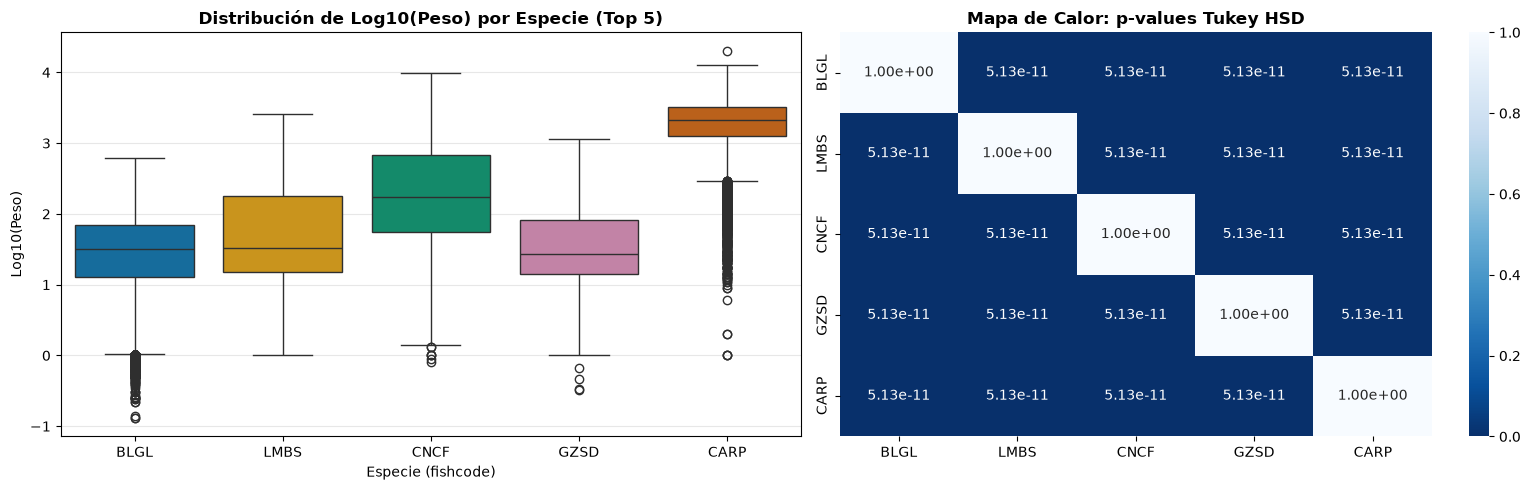

In [6]:
grupos_anova = [df_top5[df_top5['fishcode'] == esp]['log_weight'].values for esp in top5_especies]
f_stat, p_val_anova = st.f_oneway(*grupos_anova)

k = len(top5_especies)
n_tot = len(df_top5)
gl_entre = k - 1
gl_dentro = n_tot - k
f_crit_anova = st.f.ppf(0.95, gl_entre, gl_dentro)

print("--- Resultados ANOVA de un Factor (Top 5 Especies) ---")
print(f"Grados de libertad: entre = {gl_entre}, dentro = {gl_dentro}")
print(f"Estadístico F obtenido: {f_stat:.4f}")
print(f"Valor crítico F (alpha=0.05): {f_crit_anova:.4f}")
print(f"p-value: {p_val_anova:.4e}")
print(f"Decisión: {'Rechazar H0 (al menos una especie difiere en peso)' if p_val_anova < 0.05 else 'No rechazar H0'}\n")

tukey_res = st.tukey_hsd(*grupos_anova)
print("--- Matriz de p-values Post-Hoc (Tukey HSD) ---")
df_tukey = pd.DataFrame(tukey_res.pvalue, index=top5_especies, columns=top5_especies)
print(df_tukey.map(lambda x: f"{x:.4e}"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

paleta_okabe = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#D55E00']
sns.boxplot(data=df_top5, x='fishcode', y='log_weight', order=top5_especies, hue='fishcode', hue_order=top5_especies, legend=False, palette=paleta_okabe, ax=axes[0])
axes[0].set_title('Distribución de Log10(Peso) por Especie (Top 5)', fontweight='bold')
axes[0].set_xlabel('Especie (fishcode)')
axes[0].set_ylabel('Log10(Peso)')
axes[0].grid(axis='y', alpha=0.3)

sns.heatmap(tukey_res.pvalue, annot=True, fmt='.2e', cmap='Blues_r', xticklabels=top5_especies, yticklabels=top5_especies, ax=axes[1])
axes[1].set_title('Mapa de Calor: p-values Tukey HSD', fontweight='bold')

plt.tight_layout()
plt.show()

### 5. Modelos Predictivos de Peso y Tamaño según la Especie

En biología pesquera, el peso ($W$) y la longitud ($L$) de un pez siguen una relación alométrica potencial:
$$ W = a \cdot L^b $$

Al aplicar logaritmo base 10 en ambos lados, la relación se vuelve **lineal**, lo que permite entrenar modelos de Regresión Lineal Múltiple altamente precisos incorporando la especie (`fishcode`) mediante variables indicadoras (*One-Hot Encoding*):

1. **Modelo A (Predicción de Peso):** Estima `weight` (vía $\log_{10}(\text{weight})$) usando la especie y la longitud (`length`).
2. **Modelo B (Predicción de Tamaño):** Estima `length` (vía $\log_{10}(\text{length})$) usando la especie y el peso (`weight`).

Los datos se dividen en **80% entrenamiento** y **20% prueba**, evaluando las métricas $R^2$, MAE y RMSE directamente en las unidades físicas reales (gramos y milímetros).

--- Evaluación Modelo A: Predicción de Peso ---
R2 (escala log): 0.9867
R2 (escala real): 0.9435
MAE (gramos): 58.18 g
RMSE (gramos): 254.37 g

--- Evaluación Modelo B: Predicción de Tamaño ---
R2 (escala log): 0.9887
R2 (escala real): 0.9918
MAE (mm): 8.28 mm
RMSE (mm): 15.69 mm


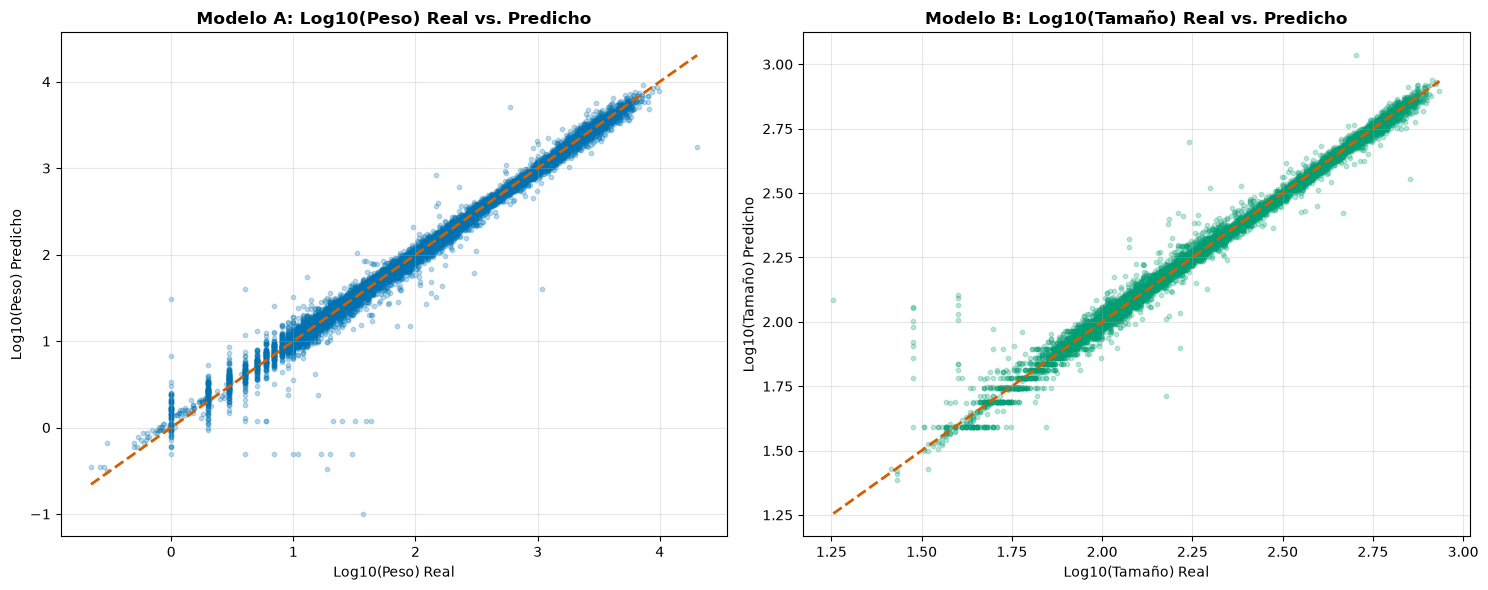

In [7]:
df_modelo = pd.get_dummies(df_top5[['fishcode', 'log_length', 'log_weight']], columns=['fishcode'], dtype=float)
cols_especies = [c for c in df_modelo.columns if c.startswith('fishcode_')]

X_peso = df_modelo[['log_length'] + cols_especies]
y_peso = df_modelo['log_weight']
Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_peso, y_peso, test_size=0.2, random_state=42)

modelo_peso = LinearRegression()
modelo_peso.fit(Xp_train, yp_train)
yp_pred_log = modelo_peso.predict(Xp_test)

yp_test_real = 10 ** yp_test
yp_pred_real = 10 ** yp_pred_log

X_tam = df_modelo[['log_weight'] + cols_especies]
y_tam = df_modelo['log_length']
Xt_train, Xt_test, yt_train, yt_test = train_test_split(X_tam, y_tam, test_size=0.2, random_state=42)

modelo_tamano = LinearRegression()
modelo_tamano.fit(Xt_train, yt_train)
yt_pred_log = modelo_tamano.predict(Xt_test)

yt_test_real = 10 ** yt_test
yt_pred_real = 10 ** yt_pred_log

print("--- Evaluación Modelo A: Predicción de Peso ---")
print(f"R2 (escala log): {r2_score(yp_test, yp_pred_log):.4f}")
print(f"R2 (escala real): {r2_score(yp_test_real, yp_pred_real):.4f}")
print(f"MAE (gramos): {mean_absolute_error(yp_test_real, yp_pred_real):.2f} g")
print(f"RMSE (gramos): {np.sqrt(mean_squared_error(yp_test_real, yp_pred_real)):.2f} g\n")

print("--- Evaluación Modelo B: Predicción de Tamaño ---")
print(f"R2 (escala log): {r2_score(yt_test, yt_pred_log):.4f}")
print(f"R2 (escala real): {r2_score(yt_test_real, yt_pred_real):.4f}")
print(f"MAE (mm): {mean_absolute_error(yt_test_real, yt_pred_real):.2f} mm")
print(f"RMSE (mm): {np.sqrt(mean_squared_error(yt_test_real, yt_pred_real)):.2f} mm")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(yp_test, yp_pred_log, alpha=0.25, s=10, color='#0072B2')
axes[0].plot([yp_test.min(), yp_test.max()], [yp_test.min(), yp_test.max()], color='#D55E00', linestyle='--', linewidth=2)
axes[0].set_title('Modelo A: Log10(Peso) Real vs. Predicho', fontweight='bold')
axes[0].set_xlabel('Log10(Peso) Real')
axes[0].set_ylabel('Log10(Peso) Predicho')
axes[0].grid(alpha=0.3)

axes[1].scatter(yt_test, yt_pred_log, alpha=0.25, s=10, color='#009E73')
axes[1].plot([yt_test.min(), yt_test.max()], [yt_test.min(), yt_test.max()], color='#D55E00', linestyle='--', linewidth=2)
axes[1].set_title('Modelo B: Log10(Tamaño) Real vs. Predicho', fontweight='bold')
axes[1].set_xlabel('Log10(Tamaño) Real')
axes[1].set_ylabel('Log10(Tamaño) Predicho')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
def predecir_peso(especie, longitud_mm):
    entrada = pd.DataFrame(0.0, index=[0], columns=X_peso.columns)
    entrada['log_length'] = np.log10(longitud_mm)
    col_esp = f'fishcode_{especie}'
    if col_esp in entrada.columns:
        entrada[col_esp] = 1.0
    return 10 ** modelo_peso.predict(entrada)[0]

def predecir_tamano(especie, peso_g):
    entrada = pd.DataFrame(0.0, index=[0], columns=X_tam.columns)
    entrada['log_weight'] = np.log10(peso_g)
    col_esp = f'fishcode_{especie}'
    if col_esp in entrada.columns:
        entrada[col_esp] = 1.0
    return 10 ** modelo_tamano.predict(entrada)[0]

for esp in top5_especies[:3]:
    peso_est = predecir_peso(esp, 200.0)
    tam_est = predecir_tamano(esp, 150.0)
    print(f"Especie {esp} | Si mide 200 mm -> Peso estimado: {peso_est:.2f} g | Si pesa 150 g -> Tamaño estimado: {tam_est:.2f} mm")

Especie BLGL | Si mide 200 mm -> Peso estimado: 169.41 g | Si pesa 150 g -> Tamaño estimado: 188.79 mm
Especie LMBS | Si mide 200 mm -> Peso estimado: 114.03 g | Si pesa 150 g -> Tamaño estimado: 216.15 mm
Especie CNCF | Si mide 200 mm -> Peso estimado: 61.71 g | Si pesa 150 g -> Tamaño estimado: 267.50 mm


### 6. Conclusiones

1. **Validez muestral y normalidad:** El tamaño de muestra del dataset LTRM supera ampliamente los requerimientos mínimos para inferencia estadística ($n_i \ge 30$ en todas las especies evaluadas). Aunque los pesos originales presentan una fuerte asimetría positiva, la transformación $\log_{10}$ estabiliza la varianza y acerca los datos a la simetría necesaria para el análisis paramétrico.
2. **Pruebas de hipótesis (T de Student y ANOVA):** Tanto la comparación pareada mediante T de Student como el ANOVA de un factor confirman diferencias estadísticamente significativas ($p < 0.05$) en el peso medio según la especie, las cuales se detallan par por par en la matriz Post-Hoc de Tukey HSD.
3. **Capacidad predictiva:** La inclusión de la especie (`fishcode`) junto con la relación alométrica logarítmica permite predecir con alto ajuste ($R^2$) tanto el peso esperado a partir de la longitud como el tamaño esperado a partir del peso.